# C3 · Final views and visual system

**Course:** Business Intelligence · IIB423T-1 · Universidad del Desarrollo
**Group:** 01 · Alessandro Lavezzi · José Saavedra
**Reading order:** (1) `W2_project.ipynb` data preparation and split → (2) `C2_classification.ipynb` model, reference and evaluation → (3) **this notebook**: the four final views, one supporting view for the internal review, and the visual rules behind them.

This notebook does not train anything. It draws the results saved in `C2_classification.ipynb` (section 3.2 coefficients, section 4.1 test-set metrics and confusion matrices). The shared rules live in `../visual_system/style.py`; every chart below imports them. View 4 uses one extra input, the persistence table by staff group and service saved in `W2_project.ipynb` (section 2.1). Figures are saved to `../figures/c3_*.png`.

## 1. Visual system: rules and where they are implemented

| Rule | Definition | Implemented in |
|---|---|---|
| Colour meaning | blue `#1F5FA8` = logistic regression; grey `#8C8C8C` = reference rule, neutral context and share ramp; amber `#D9822B` = highlight only (differences, errors, dominant factor) | `style.py` constants `C_MODEL`, `C_REF`, `C_ALERT` |
| Non-colour cues | reference rule hatched (`///`); every value printed on the mark; circle = numeric feature, diamond = category; error cells named in words | `HATCH_REF`; cells 3–7 below |
| Text | title = the finding (bold 14); subtitle = population, period and unit (9.5, grey); source line (8.5) | `heading()`, `source()` |
| Scales | scores 0–1 from zero (no truncation); shares 0–100% with the same scale in both panels; odds ratios on a log scale centred on 1 | cells 3–7 below |
| Highlighting | one highlight per view: amber differences (view 1), amber frame on the two error cells (view 2), amber dominant factor (view 3), amber frame on the staff group with the highest shares (view 4), amber differences (supporting view 5) | cells 3–7 below |
| Layout | title → subtitle → plot → legend → source; legends never cover data; reference before model, left to right | `heading()`; cells 3–7 below |

**Exceptions.** View 4 describes a different population (all people with at least 12 months on payroll, Sep 2024 – Aug 2026, from the W1/C1 analysis), not the C2 test set, so its subtitle says so. View 3 shows a different measure (odds ratio), so it has its own log scale instead of the 0–1 score scale. It keeps the colour meaning (blue = model result, amber = the one thing to notice).

**Design selection (from W3).** Views 1–3 were drawn in an earlier, weaker version and redesigned; view 4 reuses the W2 grouped-bar chart (one default colour per service) and redraws it with the same rules. The selected design was kept because each view supports one task for one audience (people-management units deciding whom to review): *compare* model and rule (view 1), *summarize* the errors (view 2), *identify* the dominant factor (view 3), *locate* where persistence is concentrated (view 4).

In [1]:
import sys
sys.path.insert(0, "../visual_system")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from pathlib import Path
import style
from style import C_MODEL, C_REF, C_ALERT, C_INK, C_GRID, HATCH_REF, CONTEXT, heading, source
style.apply()
OUT = Path("../figures"); OUT.mkdir(exist_ok=True)

## 2. Data used by the views (copied from the saved C2 outputs)
Test set: 1,192 people, 204 persistent (17.1%). Positive class = persistent. Threshold 0.35 fixed on validation. The checks below confirm the numbers add up to the C2 results.

In [2]:
metrics = pd.DataFrame({                      # C2 section 4.1, test-set metrics
    "Reference rule":      {"Precision": 0.714, "Recall": 0.760, "F1": 0.736},
    "Logistic regression": {"Precision": 0.664, "Recall": 0.833, "F1": 0.739},
}).T
cm = {                                        # C2 section 4.1: [[TP, FN], [FP, TN]]
    "Reference rule": np.array([[155, 49], [62, 926]]),
    "Logistic regression (threshold 0.35)": np.array([[170, 34], [86, 902]]),
}
odds = pd.Series({                            # C2 section 3.2, odds ratios (training fit)
    "% of months with overtime (per SD)": 5.929, "Entitled to overtime (derecho_x)": 1.914,
    "Service: Norte": 1.368, "Service: Occidente": 1.324, "Service: SurOriente": 1.296,
    "Hours per month (per SD)": 1.183, "Staff: Directivo": 0.970, "Staff: Auxiliar": 0.980,
    "Staff: Médicos y afines": 0.821, "Months on payroll (per SD)": 0.789, "Service: Oriente": 0.736,
    "Staff: Técnico": 0.633, "Staff: Profesional": 0.626, "Service: Sur": 0.461})
numeric_feats = {"% of months with overtime (per SD)", "Entitled to overtime (derecho_x)",
                 "Hours per month (per SD)", "Months on payroll (per SD)"}

# consistency checks with C2
for name, m in cm.items():
    assert m.sum() == 1192 and m[0].sum() == 204
    tp, fn, fp, tn = m[0, 0], m[0, 1], m[1, 0], m[1, 1]
    prec, rec = tp / (tp + fp), tp / (tp + fn)
    key = "Logistic regression" if "Logistic" in name else "Reference rule"
    assert abs(prec - metrics.loc[key, "Precision"]) < 0.001 and abs(rec - metrics.loc[key, "Recall"]) < 0.001
print("Checks passed: matrices add to 1,192 people (204 persistent) and agree with the metrics table.")
print(metrics.round(3).to_string())

Checks passed: matrices add to 1,192 people (204 persistent) and agree with the metrics table.
                     Precision  Recall     F1
Reference rule           0.714   0.760  0.736
Logistic regression      0.664   0.833  0.739


## 3. View 1 · Compare the model with the reference rule (task: *compare*)

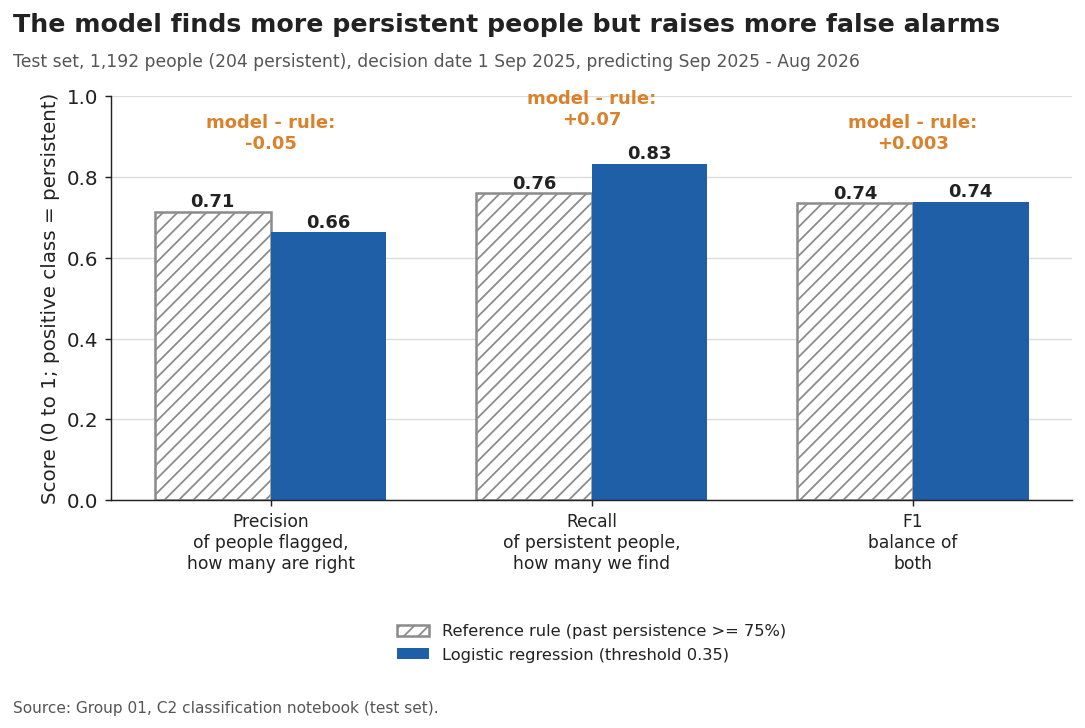

In [3]:
fig, ax = plt.subplots(figsize=(8.4, 5.6))
labels = ["Precision\nof people flagged,\nhow many are right", "Recall\nof persistent people,\nhow many we find", "F1\nbalance of\nboth"]
x = np.arange(3); w = 0.36
ref = metrics.loc["Reference rule"].values; mod = metrics.loc["Logistic regression"].values
b1 = ax.bar(x - w/2, ref, w, color="white", edgecolor=C_REF, hatch=HATCH_REF, linewidth=1.4, label="Reference rule (past persistence >= 75%)")
b2 = ax.bar(x + w/2, mod, w, color=C_MODEL, label="Logistic regression (threshold 0.35)")
for bars in (b1, b2):
    for r in bars:
        ax.text(r.get_x() + r.get_width()/2, r.get_height() + 0.012, f"{r.get_height():.2f}", ha="center", fontsize=10, fontweight="bold")
ax.set_ylim(0, 1); ax.set_yticks(np.arange(0, 1.01, 0.2)); ax.yaxis.grid(True, color=C_GRID); ax.set_axisbelow(True)
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=9.5)
ax.set_ylabel("Score (0 to 1; positive class = persistent)")
for xi, txt, yy in [(0, "-0.05", 0.87), (1, "+0.07", 0.93), (2, "+0.003", 0.87)]:
    ax.text(xi, yy, f"model - rule:\n{txt}", ha="center", color=C_ALERT, fontweight="bold", fontsize=10)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.27), ncol=1, fontsize=9)
y0 = heading(fig, "The model finds more persistent people but raises more false alarms", CONTEXT)
fig.subplots_adjust(left=0.1, right=0.98, top=y0 - 0.02, bottom=0.30)
source(fig); fig.savefig(OUT / "c3_view1_model_vs_rule.png"); plt.show()

**Reading.** Recall rises from 0.76 to 0.83 and precision falls from 0.71 to 0.66; F1 is practically equal (0.739 vs 0.736). With about 200 persistent people in the test set this difference is within sampling variation, so we do not claim that the model predicts better than the rule (C2, section 5).

## 4. View 2 · Summarize the errors (task: *summarize*)

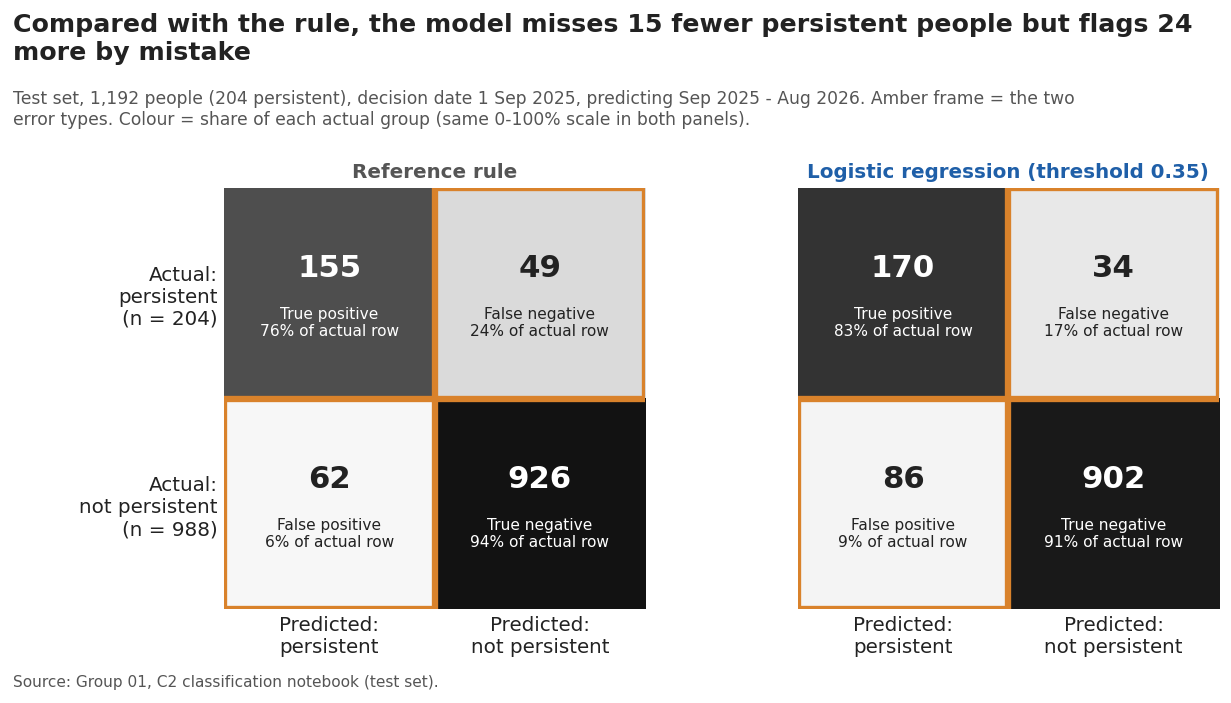

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5.4), sharey=True)
cell_names = [["True positive", "False negative"], ["False positive", "True negative"]]
for ax, name in zip(axes, ["Reference rule", "Logistic regression (threshold 0.35)"]):
    m = cm[name]; share = m / m.sum(axis=1, keepdims=True)           # share of each ACTUAL group, same 0-100% scale in both panels
    ax.imshow(share, cmap=plt.cm.Greys, vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            col = "white" if share[i, j] > 0.55 else C_INK
            ax.text(j, i - 0.12, f"{m[i, j]:,}", ha="center", va="center", fontsize=17, fontweight="bold", color=col)
            ax.text(j, i + 0.14, f"{cell_names[i][j]}\n{share[i, j]*100:.0f}% of actual row", ha="center", va="center", fontsize=8.5, color=col)
    for (i, j) in [(0, 1), (1, 0)]:                                   # the two error types
        ax.add_patch(Rectangle((j - .5, i - .5), 1, 1, fill=False, edgecolor=C_ALERT, linewidth=3.5))
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Predicted:\npersistent", "Predicted:\nnot persistent"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Actual:\npersistent\n(n = 204)", "Actual:\nnot persistent\n(n = 988)"])
    ax.tick_params(length=0)
    for s in ax.spines.values(): s.set_visible(False)
    ax.set_title(name, fontsize=11, fontweight="bold", color=C_MODEL if "Logistic" in name else "#555555", pad=6)
y0 = heading(fig, "Compared with the rule, the model misses 15 fewer persistent people but flags 24 more by mistake",
             CONTEXT + ". Amber frame = the two error types. Colour = share of each actual group (same 0-100% scale in both panels).",
             width_title=80, width_sub=120)
fig.subplots_adjust(left=0.13, right=0.98, top=y0 - 0.06, bottom=0.12, wspace=0.08)
source(fig); fig.savefig(OUT / "c3_view2_errors.png"); plt.show()

**Reading.** False negatives fall from 49 to 34 and false positives rise from 62 to 86. A false positive means a position reviewed for staffing although its overtime would not have persisted; a false negative means another year of overtime without review (C2, section 4.2).

## 5. View 3 · Identify the dominant factor (task: *identify*)

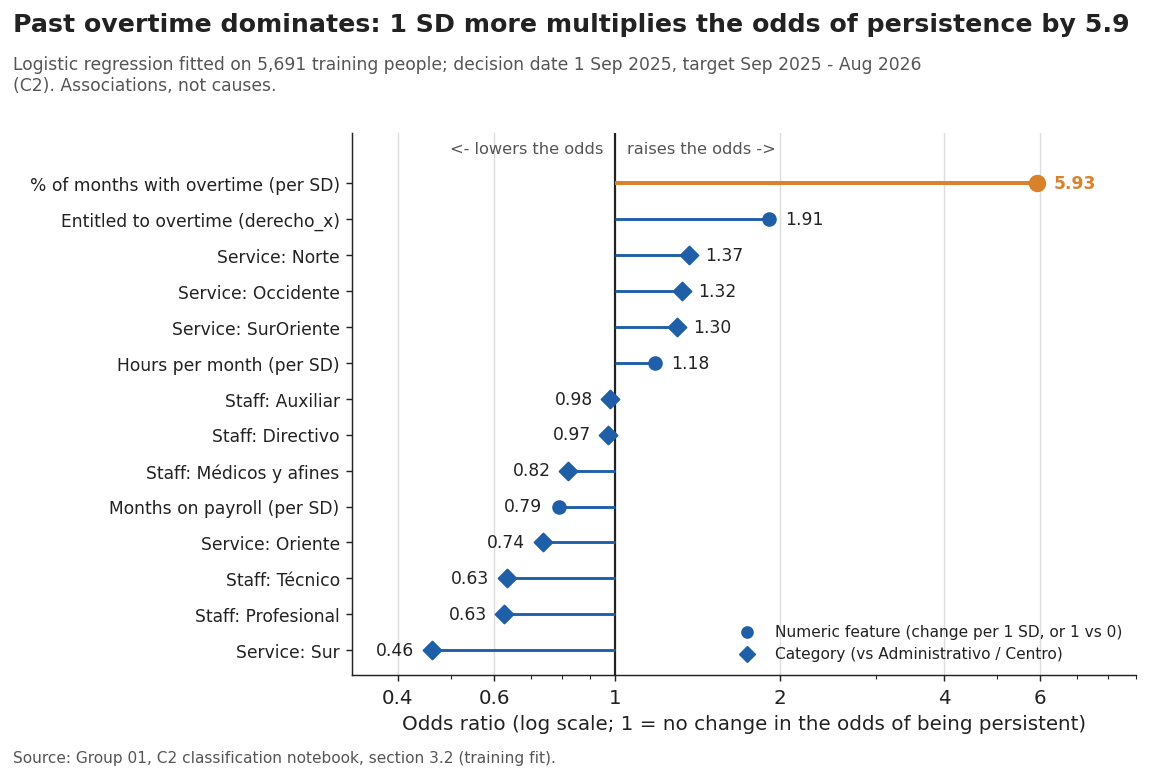

In [5]:
s = odds.sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
y = np.arange(len(s)); ax.set_xscale("log"); ax.axvline(1, color=C_INK, linewidth=1.2)
for yi, (name, v) in zip(y, s.items()):
    top = name.startswith("% of months")
    color = C_ALERT if top else C_MODEL
    ax.hlines(yi, 1, v, color=color, linewidth=2.2 if top else 1.6)
    ax.scatter(v, yi, s=75 if top else 50, color=color, marker="o" if name in numeric_feats else "D", zorder=3)
    ax.text(v * (1.07 if v >= 1 else 0.93), yi, f"{v:.2f}", va="center", ha="left" if v >= 1 else "right",
            fontsize=9.5, fontweight="bold" if top else "normal", color=C_ALERT if top else C_INK)
ax.set_yticks(y); ax.set_yticklabels(s.index, fontsize=9.5)
ax.set_xticks([0.4, 0.6, 1, 2, 4, 6]); ax.set_xticklabels(["0.4", "0.6", "1", "2", "4", "6"]); ax.set_xlim(0.33, 9)
ax.xaxis.grid(True, color=C_GRID); ax.set_axisbelow(True)
ax.set_xlabel("Odds ratio (log scale; 1 = no change in the odds of being persistent)")
ax.set_ylim(-0.7, len(s) + 0.4)
ax.text(0.95, len(s) - 0.15, "<- lowers the odds", fontsize=9, color="#555555", ha="right")
ax.text(1.05, len(s) - 0.15, "raises the odds ->", fontsize=9, color="#555555", ha="left")
ax.scatter([], [], marker="o", color=C_MODEL, label="Numeric feature (change per 1 SD, or 1 vs 0)")
ax.scatter([], [], marker="D", color=C_MODEL, label="Category (vs Administrativo / Centro)")
ax.legend(frameon=False, loc="lower right", fontsize=8.5)
y0 = heading(fig, "Past overtime dominates: 1 SD more multiplies the odds of persistence by 5.9",
             "Logistic regression fitted on 5,691 training people; decision date 1 Sep 2025, target Sep 2025 - Aug 2026 (C2). Associations, not causes.", width_title=90)
fig.subplots_adjust(left=0.30, right=0.97, top=y0 - 0.02, bottom=0.12)
source(fig, "Source: Group 01, C2 classification notebook, section 3.2 (training fit).")
fig.savefig(OUT / "c3_view3_factors.png"); plt.show()

**Reading.** The share of past months with overtime is by far the strongest signal (odds ratio 5.93 per standard deviation); that is why the one-variable reference rule is already strong. The other factors are associations, not causes.

## 6. View 4 · Locate where persistence is concentrated (task: *locate*)

In [6]:
# W2 notebook, section 2.1: people with >= 12 months on payroll (n) and persistence rate (%), by staff group and service
SERV = ["Centro", "Norte", "Oriente", "Occidente", "Sur", "SurOriente"]
GROUPS = ["Auxiliar", "Administrativo", "Técnico", "Profesional", "Médicos y afines"]
n_est = pd.DataFrame([[121, 17, 117, 77, 120, 155], [239, 59, 156, 217, 160, 198], [342, 83, 389, 375, 276, 343],
                      [724, 283, 806, 696, 505, 577], [350, 169, 347, 566, 479, 492]], index=GROUPS, columns=SERV)
rate_w2 = pd.DataFrame([[55.4, 76.5, 19.7, 44.2, 60.0, 38.1], [44.8, 49.2, 23.7, 24.0, 41.2, 41.9], [18.4, 55.4, 10.3, 20.8, 29.3, 20.1],
                        [16.3, 11.0, 6.0, 17.8, 24.4, 6.4], [2.6, 9.5, 0.9, 2.8, 1.5, 5.9]], index=GROUPS, columns=SERV)
k = (rate_w2 * n_est / 100).round().astype(int)            # persistent people per cell
rate = k / n_est * 100                                      # exact share; must agree with the saved W2 table
assert ((rate - rate_w2).abs() < 0.06).all().all(), "shares do not match the W2 table"
N_TOTAL = int(n_est.values.sum())
print(f"People with >= 12 months in these five staff groups: {N_TOTAL:,}; persistent: {k.values.sum():,} ({k.values.sum() / N_TOTAL * 100:.1f}%)")
print("Persistent people per cell (rows: staff group, columns: service):"); print(k.to_string())

People with >= 12 months in these five staff groups: 9,438; persistent: 1,580 (16.7%)
Persistent people per cell (rows: staff group, columns: service):
                  Centro  Norte  Oriente  Occidente  Sur  SurOriente
Auxiliar              67     13       23         34   72          59
Administrativo       107     29       37         52   66          83
Técnico               63     46       40         78   81          69
Profesional          118     31       48        124  123          37
Médicos y afines       9     16        3         16    7          29


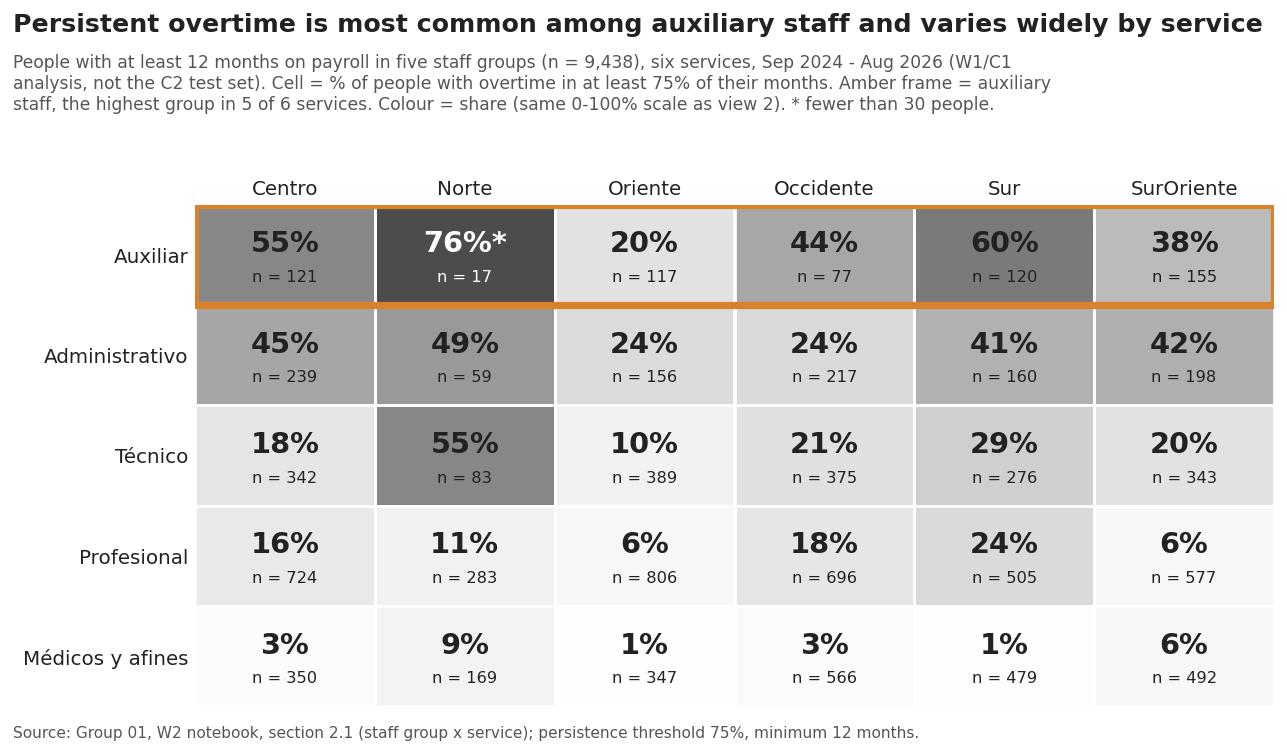

In [7]:
fig, ax = plt.subplots(figsize=(10, 5.8))
ax.imshow(rate.values / 100, cmap=plt.cm.Greys, vmin=0, vmax=1, aspect="auto")      # same 0-100% scale as view 2
for i, g in enumerate(GROUPS):
    for j, sv in enumerate(SERV):
        v, n = rate.loc[g, sv], n_est.loc[g, sv]
        col = "white" if v / 100 > 0.6 else C_INK
        ax.text(j, i - 0.11, f"{v:.0f}%" + ("*" if n < 30 else ""), ha="center", va="center", fontsize=16, fontweight="bold", color=col)
        ax.text(j, i + 0.22, f"n = {n}", ha="center", va="center", fontsize=9, color=col)
        ax.add_patch(Rectangle((j - .5, i - .5), 1, 1, fill=False, edgecolor="white", linewidth=1.5))
ax.add_patch(Rectangle((-.5, -.5), len(SERV), 1, fill=False, edgecolor=C_ALERT, linewidth=4))   # the one highlight
ax.set_xticks(range(len(SERV))); ax.set_xticklabels(SERV); ax.xaxis.tick_top()
ax.set_yticks(range(len(GROUPS))); ax.set_yticklabels(GROUPS)
ax.tick_params(length=0)
for sp in ax.spines.values(): sp.set_visible(False)
y0 = heading(fig, "Persistent overtime is most common among auxiliary staff and varies widely by service",
             f"People with at least 12 months on payroll in five staff groups (n = {N_TOTAL:,}), six services, Sep 2024 - Aug 2026 "
             "(W1/C1 analysis, not the C2 test set). Cell = % of people with overtime in at least 75% of their months. "
             "Amber frame = auxiliary staff, the highest group in 5 of 6 services. Colour = share (same 0-100% scale as view 2). "
             "* fewer than 30 people.", width_title=95, width_sub=125)
fig.subplots_adjust(left=0.15, right=0.98, top=y0 - 0.08, bottom=0.05)
source(fig, "Source: Group 01, W2 notebook, section 2.1 (staff group x service); persistence threshold 75%, minimum 12 months.")
fig.savefig(OUT / "c3_view4_staff_service.png"); plt.show()

**Reading.** In 5 of the 6 services the auxiliary group has the highest share of persistent people (in Oriente administrative staff are higher, 24% vs 20%). Médicos y afines stay low everywhere (1% to 9%). The same staff group changes a lot between services (auxiliary staff: 20% in Oriente, 60% in Sur; Norte's 76% rests on only 17 people), so the unit matters as much as the group. This supports reviewing by position and unit, which is what the model's flags are meant to rank. The shares are descriptive: they do not control for the other factors in view 3.

## 7. Supporting view for Presentation 2 · Validation versus test (task: *compare*)
This view supports the internal review: it shows why the test set was used only once and how that decision shaped the central message. Numbers from C2 sections 3.3 (validation, 1,227 people, 238 persistent) and 4.1 (test, 1,192 people, 204 persistent).

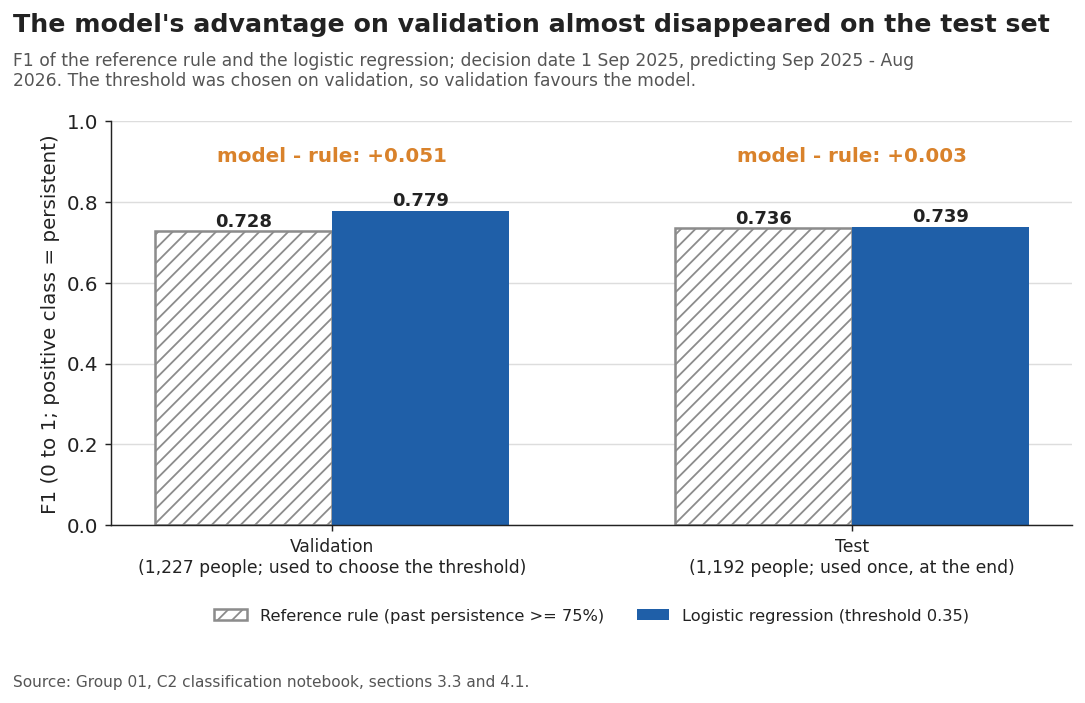

In [8]:
f1 = pd.DataFrame({"Reference rule": [0.728, 0.736], "Logistic regression": [0.779, 0.739]},
                  index=["Validation\n(1,227 people; used to choose the threshold)", "Test\n(1,192 people; used once, at the end)"])
assert abs(f1.loc[f1.index[1], "Logistic regression"] - metrics.loc["Logistic regression", "F1"]) < 0.001   # same as section 2
fig, ax = plt.subplots(figsize=(8.4, 5.4))
x = np.arange(2); w = 0.34
b1 = ax.bar(x - w/2, f1["Reference rule"], w, color="white", edgecolor=C_REF, hatch=HATCH_REF, linewidth=1.4, label="Reference rule (past persistence >= 75%)")
b2 = ax.bar(x + w/2, f1["Logistic regression"], w, color=C_MODEL, label="Logistic regression (threshold 0.35)")
for bars in (b1, b2):
    for r in bars:
        ax.text(r.get_x() + r.get_width()/2, r.get_height() + 0.012, f"{r.get_height():.3f}", ha="center", fontsize=10, fontweight="bold")
for xi in x:
    d = f1.iloc[xi]["Logistic regression"] - f1.iloc[xi]["Reference rule"]
    ax.text(xi, 0.9, f"model - rule: {d:+.3f}", ha="center", color=C_ALERT, fontweight="bold", fontsize=11)
ax.set_ylim(0, 1); ax.set_yticks(np.arange(0, 1.01, 0.2)); ax.yaxis.grid(True, color=C_GRID); ax.set_axisbelow(True)
ax.set_xticks(x); ax.set_xticklabels(f1.index, fontsize=9.5)
ax.set_ylabel("F1 (0 to 1; positive class = persistent)")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, fontsize=9)
y0 = heading(fig, "The model's advantage on validation almost disappeared on the test set",
             "F1 of the reference rule and the logistic regression; decision date 1 Sep 2025, predicting Sep 2025 - Aug 2026. "
             "The threshold was chosen on validation, so validation favours the model.", width_title=80)
fig.subplots_adjust(left=0.1, right=0.98, top=y0 - 0.02, bottom=0.24)
source(fig, "Source: Group 01, C2 classification notebook, sections 3.3 and 4.1.")
fig.savefig(OUT / "c3_view5_validation_vs_test.png"); plt.show()

**Reading.** On validation the model looked clearly better (+0.051 in F1), but the threshold had been chosen on those same people. On the untouched test set the gain is +0.003. Because we used the test set only once, we report this result instead of the validation one, and the central message becomes "the model changes the trade-off; it does not clearly predict better".

## 8. Limits of these views
- **View 1** hides the uncertainty of the metrics (about 200 persistent people); confidence intervals would need person-level predictions.
- **View 2** shows shares per actual group, which can make false positives (9%) look small although they are 86 people in total (24 more than the 62 of the rule).
- **View 3** mixes per-standard-deviation effects and category-vs-reference effects; shapes flag this but do not make them directly comparable.
- **View 4** describes all people with at least 12 months over the full period, not the prediction setting of views 1–3, and small cells (Auxiliar in Norte, 17 people) can show extreme shares; the printed n and the asterisk flag this.